In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [4]:
df_customer=pd.read_csv('data/customers.csv')
df_loan=pd.read_csv('data/loans.csv')
df_bureau=pd.read_csv('data/bureau_data.csv')

In [5]:
print(df_bureau.shape)
print(df_customer.shape)
print(df_loan.shape)

(50000, 8)
(50000, 12)
(50000, 15)


In [6]:
df_loan.head(5)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,L00003,C00003,Personal,Unsecured,2401000,2170000,43400.0,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,L00004,C00004,Personal,Unsecured,2345000,1747000,34940.0,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,L00005,C00005,Auto,Secured,4647000,4520000,90400.0,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [7]:
df_customer.head(5)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,Karnataka,560001
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,Maharashtra,411001


In [8]:
df_bureau.head(5)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4
2,C00003,2,1,82,24,147,6,58
3,C00004,3,0,115,15,87,5,26
4,C00005,4,2,120,0,0,5,10


# Megring dataset using primary key

In [9]:
df = pd.merge(df_bureau, df_customer, on='cust_id')#at once we can only merge 1 dataset
df = pd.merge(df, df_loan, on='cust_id')

df.head(3)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,1,1,42,0,0,3,7,44,M,...,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,3,1,96,12,60,5,4,38,M,...,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,2,1,82,24,147,6,58,46,F,...,2170000,43400.0,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False


In [10]:
df.shape

(50000, 33)

In [11]:
df.dtypes

cust_id                         object
number_of_open_accounts          int64
number_of_closed_accounts        int64
total_loan_months                int64
delinquent_months                int64
total_dpd                        int64
enquiry_count                    int64
credit_utilization_ratio         int64
age                              int64
gender                          object
marital_status                  object
employment_status               object
income                           int64
number_of_dependants             int64
residence_type                  object
years_at_current_address         int64
city                            object
state                           object
zipcode                          int64
loan_id                         object
loan_purpose                    object
loan_type                       object
sanction_amount                  int64
loan_amount                      int64
processing_fee                 float64
gst                      

In [12]:
df['default']=df['default'].astype(int)
df['default'].value_counts()# from this we can see class imbalance

default
0    45703
1     4297
Name: count, dtype: int64

In [13]:
df.describe()

,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,income,number_of_dependants,...,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,default
count,50000.000000,50000.00000,50000.000000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,5.000000e+04,50000.000000,...,50000.000000,5.000000e+04,5.000000e+04,5.000000e+04,5.000000e+04,5.000000e+04,50000.000000,5.000000e+04,5.000000e+04,50000.000000
mean,2.500140,1.00106,76.127140,4.87890,26.858000,5.009340,43.36142,39.550980,2.640898e+06,1.939540,...,419090.860000,4.704828e+06,3.999679e+06,8.049471e+04,7.199422e+05,3.199743e+06,25.940520,1.337636e+06,9.891264e+05,0.085940
std,1.118725,0.81412,43.762469,5.85032,32.832832,2.029122,29.35598,9.847752,2.629441e+06,1.535517,...,168982.674047,6.267276e+06,5.376552e+06,1.173123e+05,9.677794e+05,4.301242e+06,12.433163,1.214714e+06,1.046072e+06,0.280278
min,1.000000,0.00000,1.000000,0.00000,0.000000,1.000000,0.00000,18.000000,0.000000e+00,0.000000,...,110001.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.000000,-1.000000e+00,0.000000e+00,0.000000
25%,1.000000,0.00000,42.000000,0.00000,0.000000,4.000000,18.00000,33.000000,8.030000e+05,0.000000,...,302001.000000,1.147000e+06,9.670000e+05,1.934000e+04,1.740600e+05,7.736000e+05,16.000000,4.247990e+05,2.870075e+05,0.000000
50%,3.000000,1.00000,71.000000,3.00000,14.000000,5.000000,39.00000,40.000000,1.892000e+06,2.000000,...,400001.000000,2.656000e+06,2.240000e+06,4.480000e+04,4.032000e+05,1.792000e+06,24.000000,1.002309e+06,6.685250e+05,0.000000
75%,4.000000,2.00000,107.000000,9.00000,46.000000,6.000000,67.00000,46.000000,3.332250e+06,3.000000,...,560001.000000,5.172250e+06,4.611000e+06,9.224000e+04,8.299800e+05,3.688800e+06,35.000000,1.790751e+06,1.238667e+06,0.000000
max,4.000000,2.00000,223.000000,24.00000,171.000000,9.000000,99.00000,70.000000,1.199900e+07,5.000000,...,700001.000000,5.217500e+07,4.781900e+07,5.698030e+06,8.607420e+06,3.825520e+07,59.000000,5.000000e+06,7.846643e+06,1.000000


# Splitting data to avoid data leakage

In [14]:
x=df.drop('default',axis=1)
y=df.default

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.25,random_state=42)

In [15]:
df_train=pd.concat([x_train,y_train],axis=1)
df_test=pd.concat([x_test,y_test],axis=1)

df_train.shape,df_test.shape

((37500, 33), (12500, 33))

In [16]:
df_train.isna().sum()

cust_id                         0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd                       0
enquiry_count                   0
credit_utilization_ratio        0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 48
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_a

In [17]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented', nan], dtype=object)

In [18]:
# for train data set
mode_residence = df_train['residence_type'].mode().iloc[0]
df_train['residence_type'] = df_train['residence_type'].fillna(mode_residence)# replacing null values with mode value

In [19]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented'], dtype=object)

In [20]:
# for test data set
mode_residence = df_test['residence_type'].mode().iloc[0]
df_test['residence_type'] = df_test['residence_type'].fillna(mode_residence)# replacing null values with mode value

In [21]:
df_test.residence_type.unique()

array(['Owned', 'Rented', 'Mortgage'], dtype=object)

In [22]:
df_train.duplicated().sum()

np.int64(0)

# Removing Outliers

In [23]:
int_cols = ['age', 'income', 'number_of_dependants', 'years_at_current_address', 
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 
                      'loan_tenure_months','principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts','number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

cat_cols = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']

In [24]:
import math

## numarical columns

### box plot

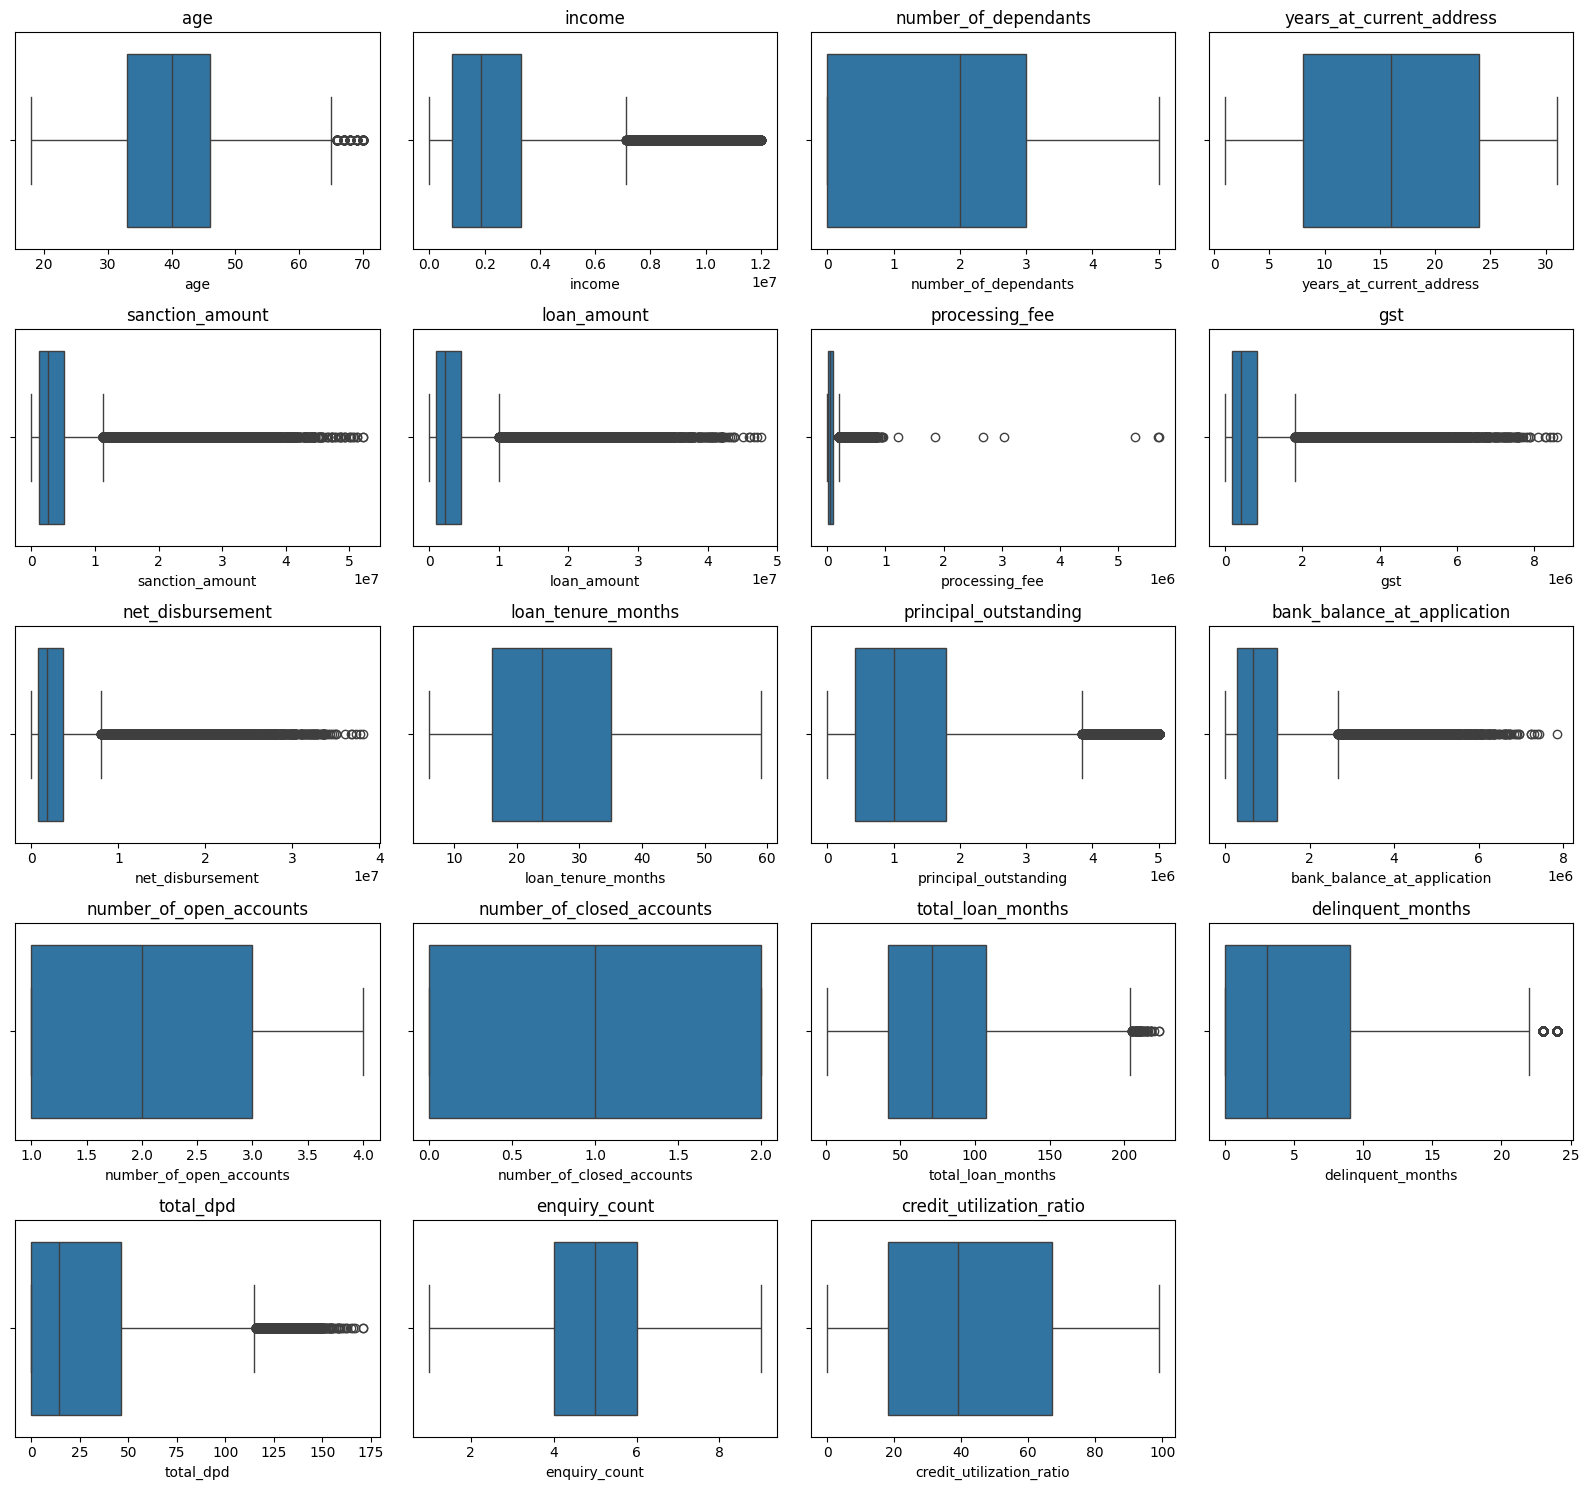

In [25]:
#for train data set
n_cols = 4
n_rows = math.ceil(len(int_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows))
axes = axes.flatten()
for i, col in enumerate(int_cols):
    sns.boxplot(data=df_train, x=col, ax=axes[i])
    axes[i].set_title(col)
# Remove empty subplots
for j in range(len(int_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


### hist plot

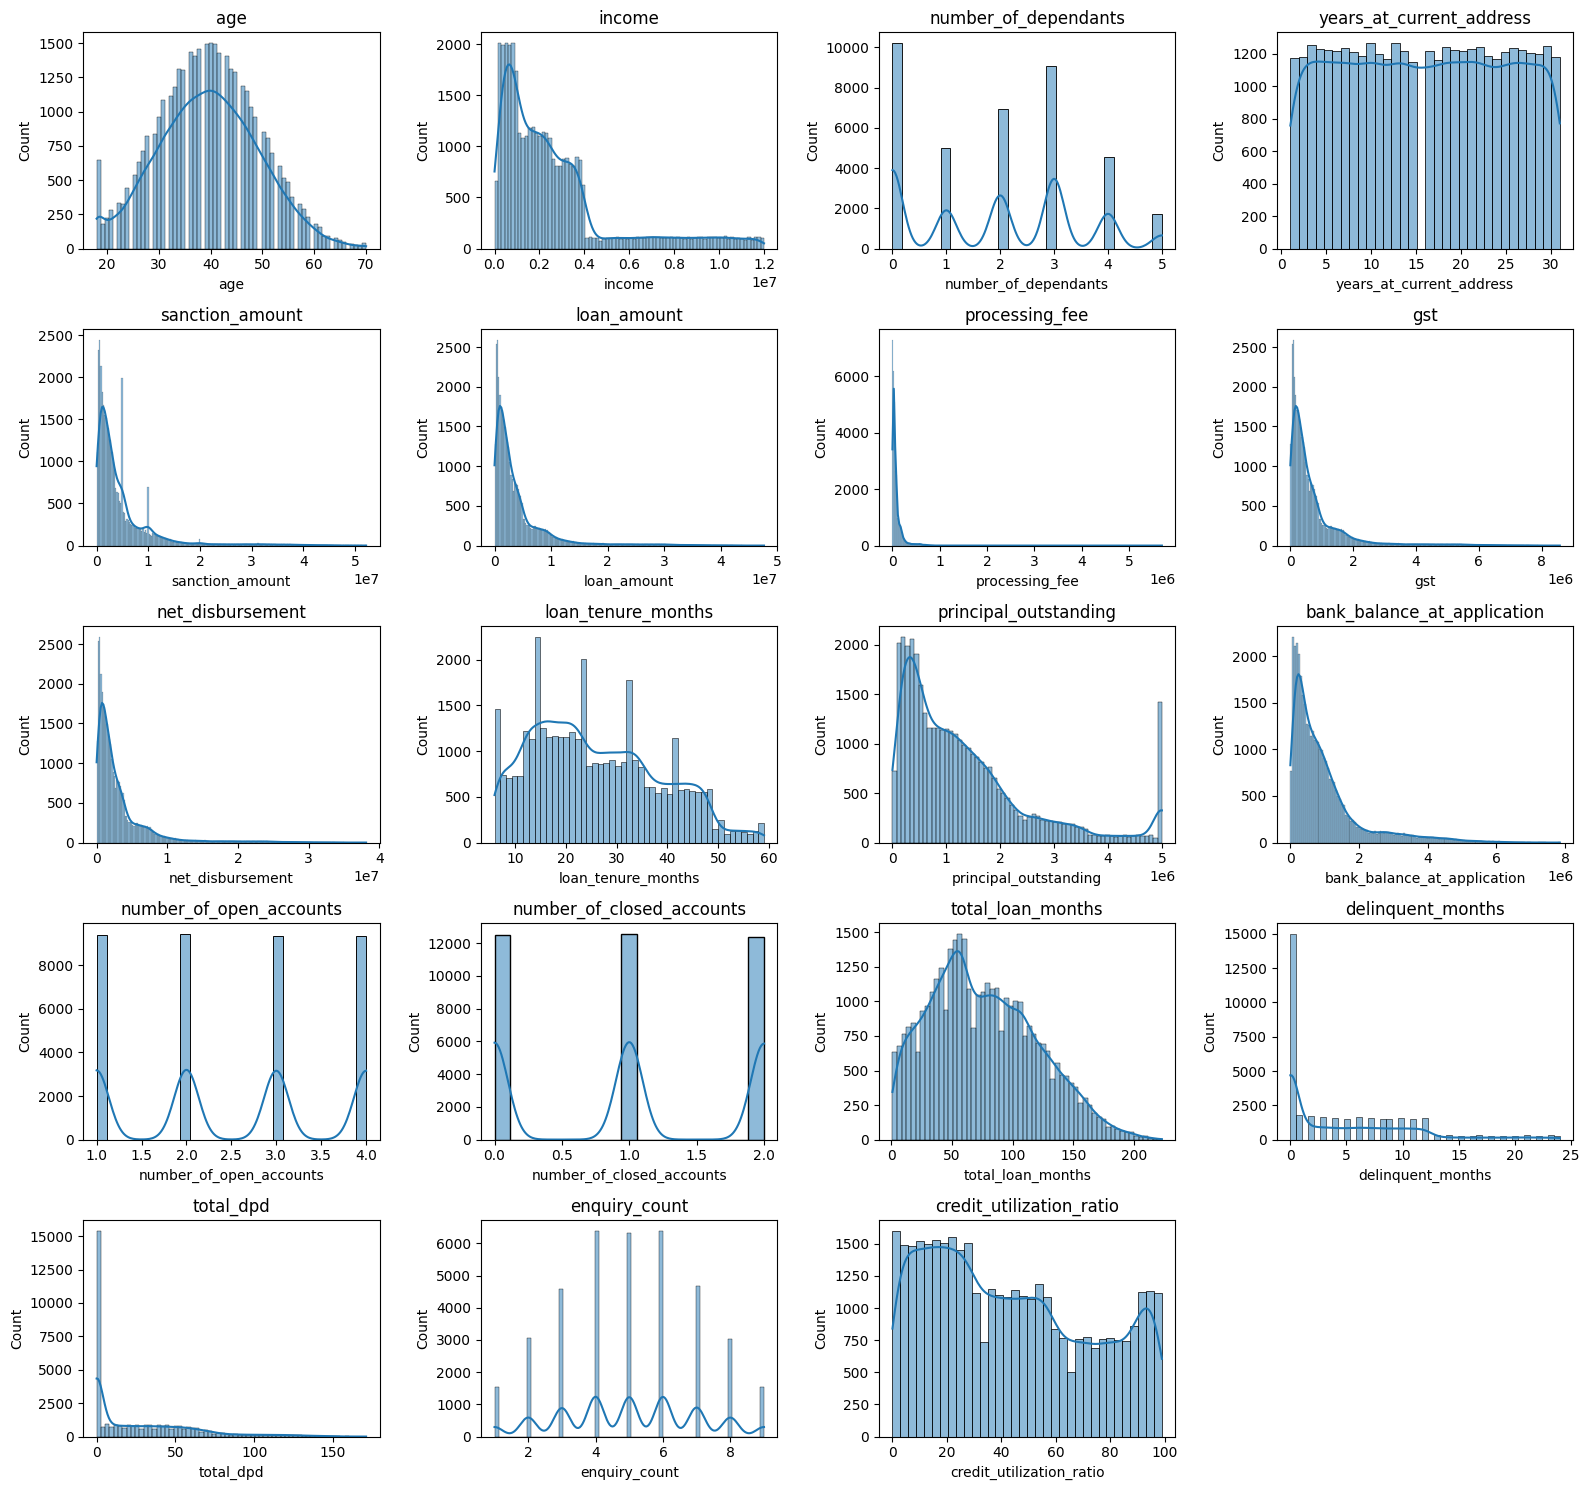

In [26]:
#for train data set
n_cols = 4
n_rows = math.ceil(len(int_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows))
axes = axes.flatten()
for i, col in enumerate(int_cols):
    sns.histplot(df_train[col],kde=True, ax=axes[i])
    axes[i].set_title(col)
# Remove empty subplots
for j in range(len(int_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


In [27]:
df_train.processing_fee.describe()

count    3.750000e+04
mean     8.072411e+04
std      1.208307e+05
min      0.000000e+00
25%      1.918000e+04
50%      4.470000e+04
75%      9.200000e+04
max      5.698030e+06
Name: processing_fee, dtype: float64

In [28]:
df_train[df_train.processing_fee>df_train.loan_amount][['loan_amount','processing_fee']]# processing fee can't be >then loan amount

,loan_amount,processing_fee
23981,2234000,2.669791e+06
9898,3626000,5.293544e+06
47089,1738000,1.858965e+06
33705,3812000,5.678021e+06
12294,4639000,5.698030e+06
28174,966000,1.214493e+06
29305,2616000,3.036378e+06


In [29]:
df_train[(df_train.processing_fee/df_train.loan_amount)>0.03][['loan_amount','processing_fee']]# processing fee is 3% of loan amount

,loan_amount,processing_fee
23981,2234000,2.669791e+06
9898,3626000,5.293544e+06
47089,1738000,1.858965e+06
33705,3812000,5.678021e+06
12294,4639000,5.698030e+06
28174,966000,1.214493e+06
29305,2616000,3.036378e+06


In [30]:
df_train1=df_train[(df_train.processing_fee/df_train.loan_amount)<0.03].copy()
df_train1[(df_train1.processing_fee/df_train1.loan_amount)>0.03]

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default


In [31]:
df_test[(df_test.processing_fee/df_test.loan_amount)>0.03]#no outliers in test dataset

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default


## categorical columns

In [32]:
for i in cat_cols:
    print(i,'-->' ,df_train[i].unique())

gender --> ['F' 'M']
marital_status --> ['Single' 'Married']
employment_status --> ['Salaried' 'Self-Employed']
residence_type --> ['Owned' 'Mortgage' 'Rented']
city --> ['Ahmedabad' 'Delhi' 'Lucknow' 'Bangalore' 'Jaipur' 'Hyderabad' 'Kolkata'
 'Pune' 'Chennai' 'Mumbai']
state --> ['Gujarat' 'Delhi' 'Uttar Pradesh' 'Karnataka' 'Rajasthan' 'Telangana'
 'West Bengal' 'Maharashtra' 'Tamil Nadu']
zipcode --> [380001 110001 226001 560001 302001 500001 700001 411001 600001 400001]
loan_purpose --> ['Home' 'Auto' 'Personal' 'Education' 'Personaal']
loan_type --> ['Secured' 'Unsecured']
default --> [0 1]


In [33]:
for i in cat_cols:
    print(i,'-->' ,df_test[i].unique())

gender --> ['F' 'M']
marital_status --> ['Married' 'Single']
employment_status --> ['Self-Employed' 'Salaried']
residence_type --> ['Owned' 'Rented' 'Mortgage']
city --> ['Hyderabad' 'Jaipur' 'Delhi' 'Pune' 'Chennai' 'Ahmedabad' 'Lucknow'
 'Kolkata' 'Bangalore' 'Mumbai']
state --> ['Telangana' 'Rajasthan' 'Delhi' 'Maharashtra' 'Tamil Nadu' 'Gujarat'
 'Uttar Pradesh' 'West Bengal' 'Karnataka']
zipcode --> [500001 302001 110001 411001 600001 380001 226001 700001 560001 400001]
loan_purpose --> ['Education' 'Home' 'Auto' 'Personal' 'Personaal']
loan_type --> ['Secured' 'Unsecured']
default --> [0 1]


In [34]:
df_train1['loan_purpose'].unique()

array(['Home', 'Auto', 'Personal', 'Education', 'Personaal'], dtype=object)

In [35]:
df_train1['loan_purpose'].replace('Personaal','Personal',inplace=True)
df_train1['loan_purpose'].unique()

C:\Users\Jeevan kumar\AppData\Local\Temp\ipykernel_2036\321029324.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train1['loan_purpose'].replace('Personaal','Personal',inplace=True)


array(['Home', 'Auto', 'Personal', 'Education'], dtype=object)

In [36]:
df_test['loan_purpose'].replace('Personaal','Personal',inplace=True)
df_test['loan_purpose'].unique()

C:\Users\Jeevan kumar\AppData\Local\Temp\ipykernel_2036\1121104804.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_test['loan_purpose'].replace('Personaal','Personal',inplace=True)


array(['Education', 'Home', 'Auto', 'Personal'], dtype=object)

In [37]:
df_train1[(df_train1.gst/df_train1.loan_amount)>18]

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default


# EDA

In [42]:
df_train1.groupby("default")['age'].describe()

,count,mean,std,min,25%,50%,75%,max
default,,,,,,,,
0,34298.0,39.778413,9.870763,18.0,33.0,40.0,47.0,70.0
1,3189.0,37.250862,9.372791,18.0,31.0,37.0,44.0,70.0


**Insights**

1. Average age in the default group is little less (37.12) than the average (39.7) of the group that did not default
1. Variability (standard deviation) is mostly similar in both the groups
1. Both the groups have similar min and max ages

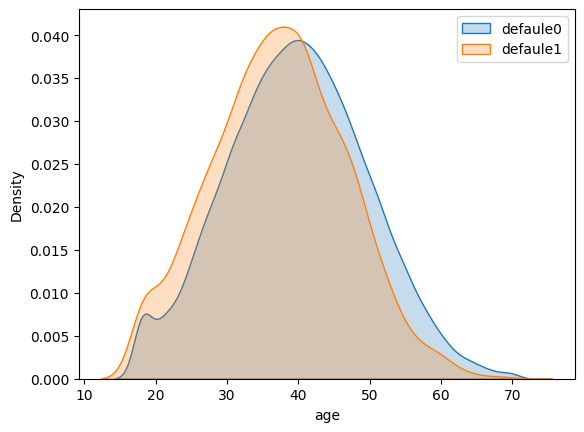

In [38]:
sns.kdeplot(df_train1[df_train1.default==0]['age'],fill=True,label='defaule0')
sns.kdeplot(df_train1[df_train1.default==1]['age'],fill=True,label='defaule1')
plt.legend()
plt.show()

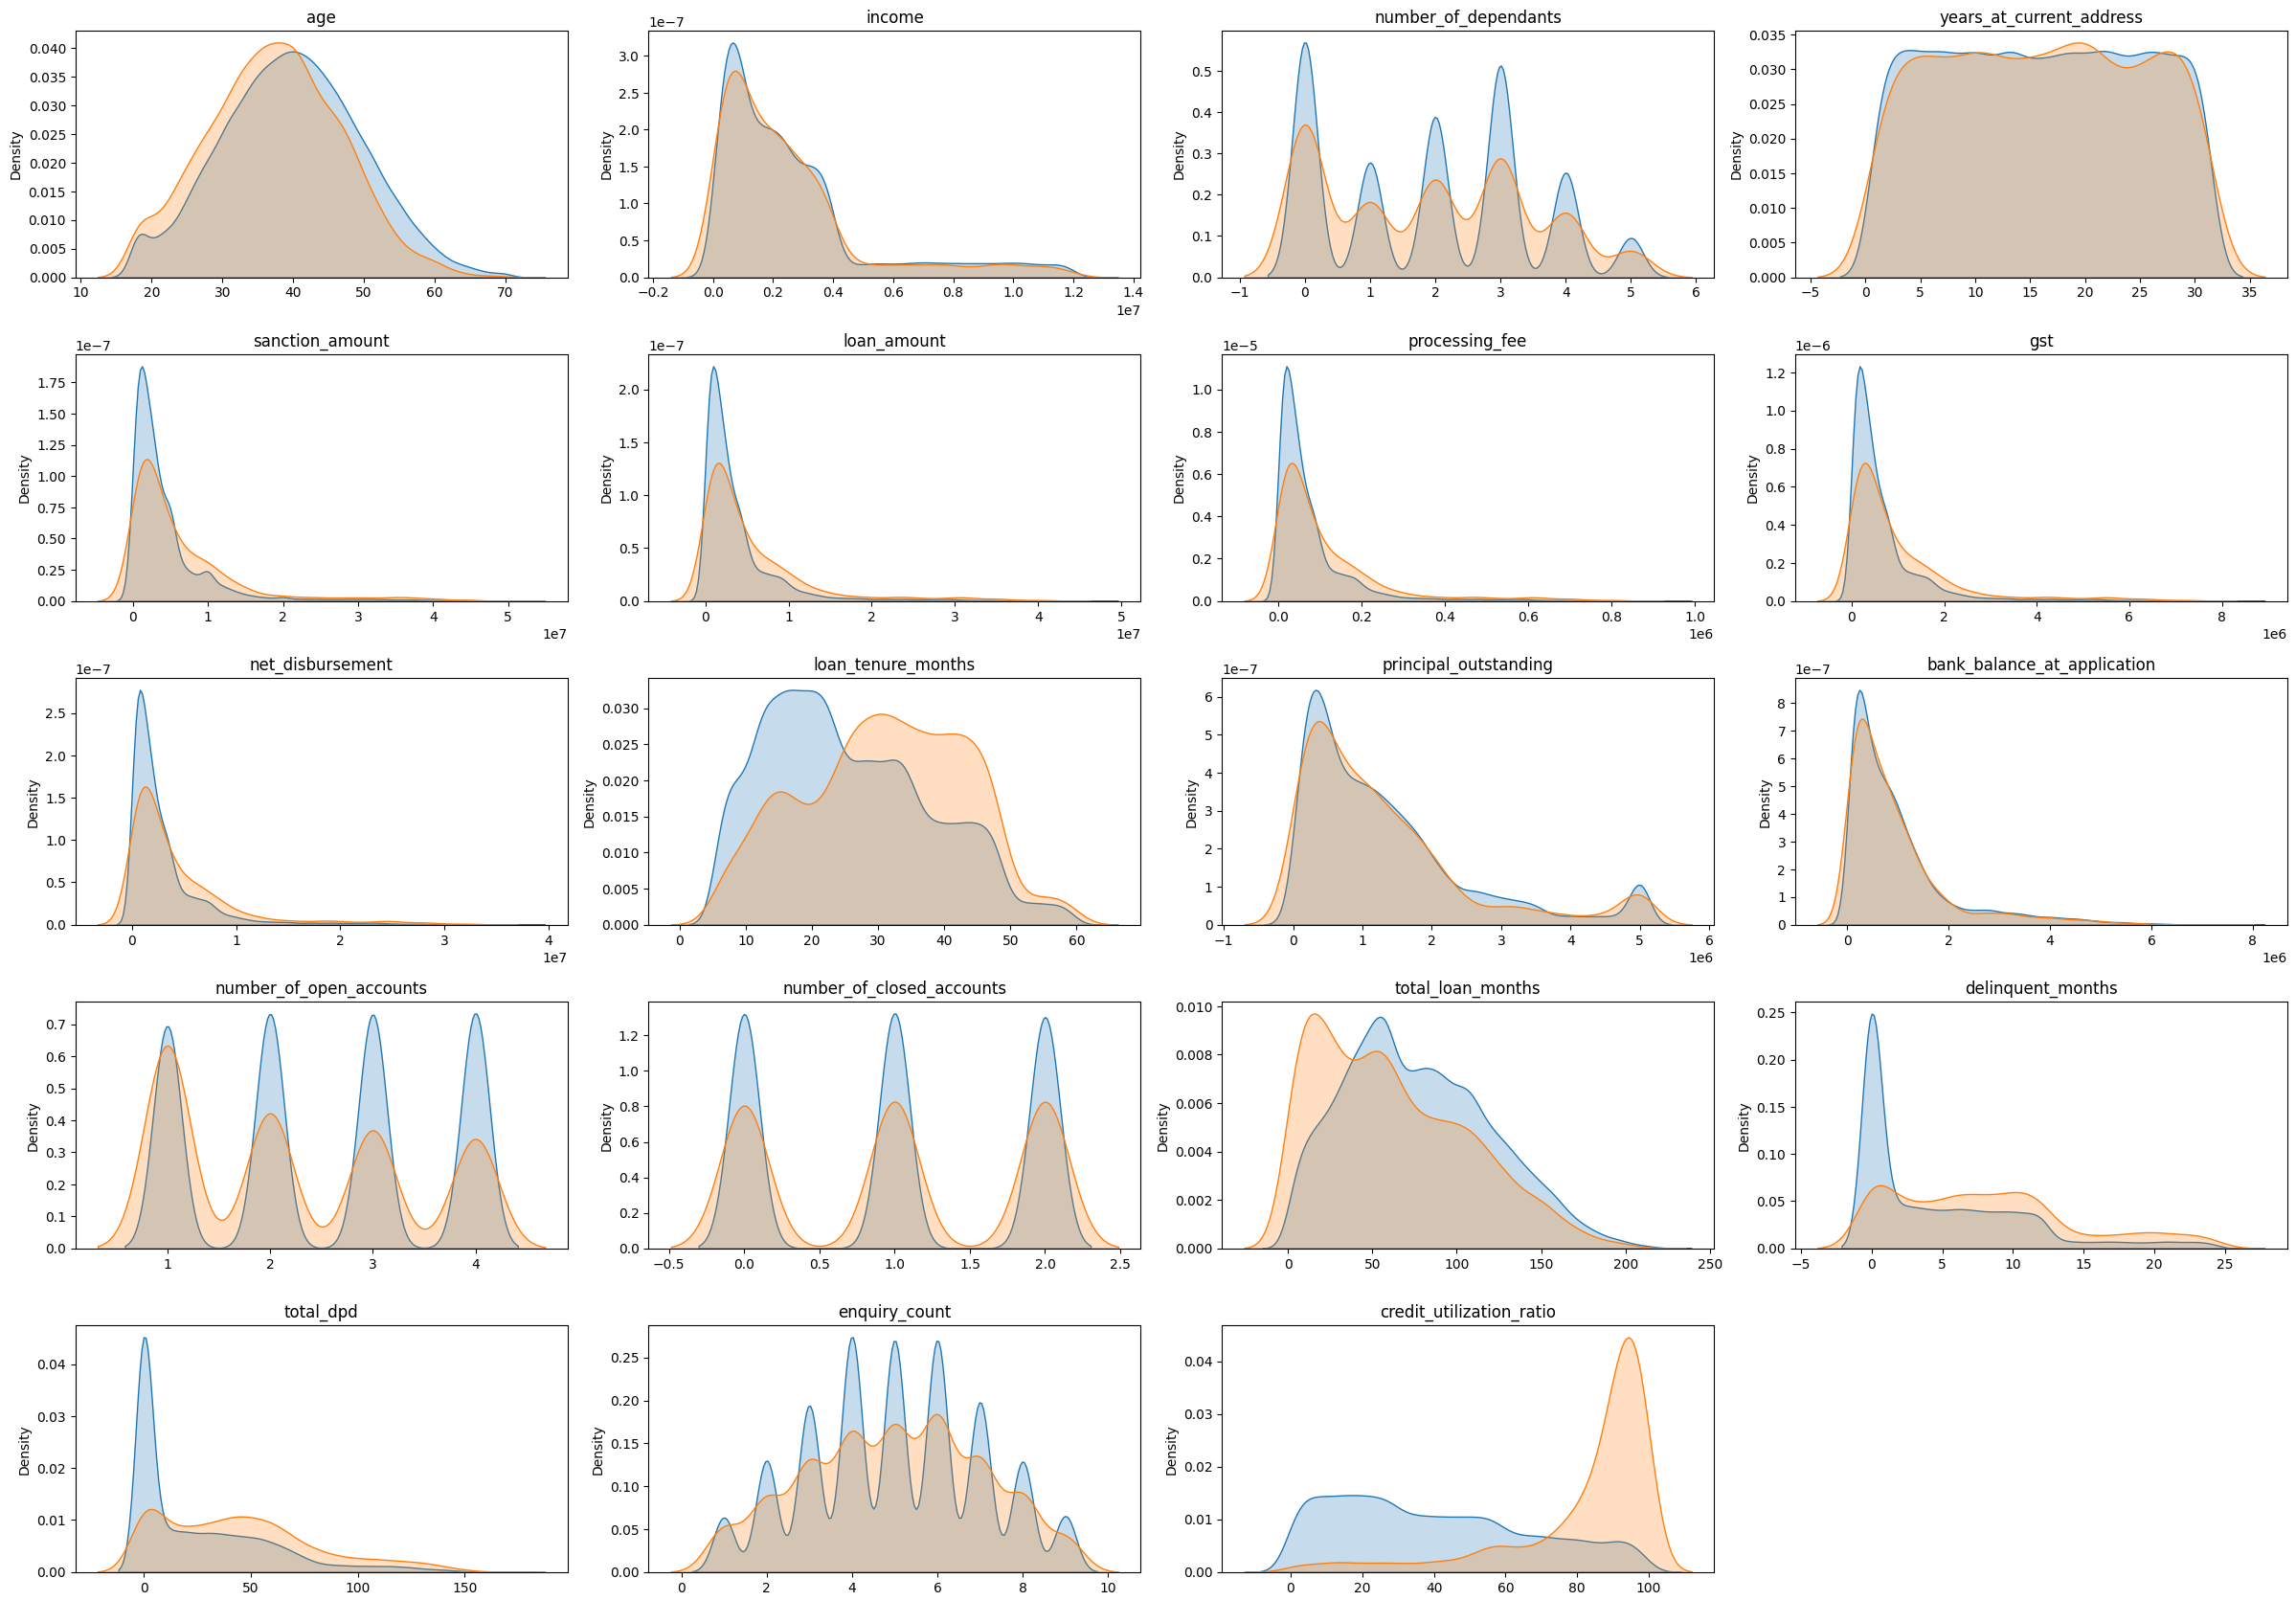

In [39]:
plt.figure(figsize=(24,20))

for i,col in enumerate(int_cols):
    plt.subplot(6,4,i+1)
    sns.kdeplot(df_train1[col][df_train1.default==0],fill=True,label='defaule0')
    sns.kdeplot(df_train1[col][df_train1.default==1],fill=True,label='defaule1')
    plt.title(col)
    plt.xlabel(' ')

plt.tight_layout()
plt.show()

**Insights**

1. In columns: loan_tenure_months, delinquent_months, total_dpd, credit_utilization, higher values indicate high likelyhood of becoming a default. Hence these 4 looks like strong predictors
1. In remaining columns the distributions do not give any obvious insights
1. Why loan_amount and income did not give any signs of being strong predictors? May be when we combine these two and get loan to income ratio (LTI), that may have influence on the target variable. We will explore more later

# Feature engineering and Feature selection

**Insights**
1. Blue graph has majority of its values on lower side of LTI
2. Orange graph has many values when LTI is higher indicating that higher LTI means high risk loan

**Insights**
1. Blue graph has majority of its values on lower side of LTI
2. Orange graph has many values when delinquency ratio is higher indicating some correlation on default

**Insights**

1. Graph clearly shows more occurances of default cases when avg_dpd_per_delinquency is high. This means this column is a strong predictor